In [82]:
import openeo

# Connect to the Copernicus Data Space openEO backend
connection = openeo.connect(
    "https://openeo.dataspace.copernicus.eu"
)

# Check the backend connection
print(connection.capabilities().api_version())

1.2.0


In [83]:
# Authenticate with Copernicus Data Space
connection.authenticate_oidc()

print("Authentication successful")

Authenticated using refresh token.
Authentication successful


In [84]:
# Define the Ahr Valley study area (WGS84)
bbox = {
    "west": 6.90,
    "south": 50.48,
    "east": 7.16,
    "north": 50.59
}

# Define selected acquisition periods
before_flood = ["2021-07-09", "2021-07-10"]
after_flood = ["2021-07-15", "2021-07-16"]

# Define the relative orbit
relative_orbit = 37

print("Study area:", bbox)
print("Before flood:", before_flood)
print("After flood:", after_flood)
print("Relative orbit:", relative_orbit)

Study area: {'west': 6.9, 'south': 50.48, 'east': 7.16, 'north': 50.59}
Before flood: ['2021-07-09', '2021-07-10']
After flood: ['2021-07-15', '2021-07-16']
Relative orbit: 37


In [85]:
import requests
from shapely.geometry import box, shape

# Search Sentinel-1 GRD acquisition metadata
response = requests.post(
    "https://stac.dataspace.copernicus.eu/v1/search",
    json={
        "collections": ["sentinel-1-grd"],
        "bbox": [
            bbox["west"],
            bbox["south"],
            bbox["east"],
            bbox["north"]
        ],
        "datetime": "2021-07-01T00:00:00Z/2021-07-26T23:59:59Z",
        "limit": 100
    },
    timeout=60
)

response.raise_for_status()
scenes = response.json()["features"]

# Define the study area geometry
aoi = box(
    bbox["west"],
    bbox["south"],
    bbox["east"],
    bbox["north"]
)

print("Total Sentinel-1 scenes:", len(scenes))
print("-" * 100)

# Inspect dates, orbits, polarizations and coverage
for scene in sorted(
    scenes,
    key=lambda item: item["properties"]["datetime"]
):
    props = scene["properties"]

    print(
        f"Date: {props['datetime'][:10]} | "
        f"Orbit: {props.get('sat:relative_orbit')} | "
        f"Direction: {props.get('sat:orbit_state')} | "
        f"Polarizations: {props.get('sar:polarizations')} | "
        f"Full coverage: {shape(scene['geometry']).covers(aoi)}"
    )

# Verify the selected acquisitions
print("\nSELECTED ACQUISITIONS")
print("-" * 100)

for target_date in [before_flood[0], after_flood[0]]:
    matches = [
        scene for scene in scenes
        if scene["properties"]["datetime"].startswith(target_date)
        and scene["properties"].get("sat:relative_orbit") == relative_orbit
        and "VV" in scene["properties"].get("sar:polarizations", [])
        and shape(scene["geometry"]).covers(aoi)
    ]

    print(
        f"{target_date} | "
        f"Orbit {relative_orbit} | "
        f"Valid scenes: {len(matches)}"
    )

    if not matches:
        raise ValueError(f"No suitable acquisition for {target_date}")

Total Sentinel-1 scenes: 16
----------------------------------------------------------------------------------------------------
Date: 2021-07-01 | Orbit: 15 | Direction: ascending | Polarizations: ['VV', 'VH'] | Full coverage: True
Date: 2021-07-03 | Orbit: 37 | Direction: descending | Polarizations: ['VV', 'VH'] | Full coverage: True
Date: 2021-07-06 | Orbit: 88 | Direction: ascending | Polarizations: ['VV', 'VH'] | Full coverage: True
Date: 2021-07-07 | Orbit: 15 | Direction: ascending | Polarizations: ['VV', 'VH'] | Full coverage: True
Date: 2021-07-09 | Orbit: 37 | Direction: descending | Polarizations: ['VV', 'VH'] | Full coverage: True
Date: 2021-07-10 | Orbit: 139 | Direction: descending | Polarizations: ['VV', 'VH'] | Full coverage: True
Date: 2021-07-12 | Orbit: 88 | Direction: ascending | Polarizations: ['VV', 'VH'] | Full coverage: True
Date: 2021-07-13 | Orbit: 15 | Direction: ascending | Polarizations: ['VV', 'VH'] | Full coverage: True
Date: 2021-07-15 | Orbit: 37 | Dire

In [86]:
# Load both Sentinel-1 acquisitions into one data cube
s1_cube = connection.load_collection(
    "SENTINEL1_GRD",
    spatial_extent=bbox,
    temporal_extent=[before_flood[0], after_flood[1]],
    bands=["VV"],
    properties={
        "sat:relative_orbit": lambda orbit: orbit == relative_orbit
    }
)

# Apply SAR calibration once
s1_cube = s1_cube.sar_backscatter(
    coefficient="sigma0-ellipsoid"
)

print(s1_cube)

DataCube(<PGNode 'sar_backscatter' at 0x2462d5dfcf0>)


In [87]:
# Select the pre-flood and post-flood acquisitions
s1_before = s1_cube.filter_temporal(*before_flood)
s1_after = s1_cube.filter_temporal(*after_flood)

print("Before:", s1_before)
print("After:", s1_after)

Before: DataCube(<PGNode 'filter_temporal' at 0x2462d5cd090>)
After: DataCube(<PGNode 'filter_temporal' at 0x246293d3750>)


In [88]:
# Convert each temporal selection to one spatial raster
before_vv = s1_before.reduce_dimension(
    dimension="t",
    reducer="mean"
)

after_vv = s1_after.reduce_dimension(
    dimension="t",
    reducer="mean"
)

print("Before raster:", before_vv)
print("After raster:", after_vv)

Before raster: DataCube(<ReduceNode 'reduce_dimension' at 0x24631719360>)
After raster: DataCube(<ReduceNode 'reduce_dimension' at 0x2463171b110>)


In [89]:
# Calculate VV backscatter change in decibels
vv_change_db = 10 * (after_vv / before_vv).log10()

print(vv_change_db)

DataCube(<PGNode 'apply' at 0x246293d2fd0>)


In [90]:
# Validate the change detection workflow
validation = vv_change_db.validate()

print("Validation:", validation)

Validation: []


In [92]:
# Create a new processing job
change_job = vv_change_db.create_job(
    out_format="GTiff",
    title="Ahr Valley VV Change - Orbit 37 - July 9-15"
)

print("Job ID:", change_job.job_id)
print("Job status:", change_job.status())

Job ID: j-2610151543044c66be94c60adf81d9ef
Job status: created


In [93]:
# Start the Sentinel-1 processing job
change_job.start_job()

<BatchJob job_id='j-2610151543044c66be94c60adf81d9ef'>

In [95]:
print("Job status:", change_job.status())

Job status: finished


In [96]:
from pathlib import Path

# Download results into an Orbit 37 output directory
output_dir = Path("outputs/orbit37")
output_dir.mkdir(parents=True, exist_ok=True)

if change_job.status() != "finished":
    raise RuntimeError("Processing job is not finished")

results = change_job.get_results()
downloaded_files = results.download_files(target=output_dir)

for file in downloaded_files:
    print("Downloaded:", file)

raster_path = output_dir / "openEO.tif"

Downloaded: outputs\orbit37\openEO.tif
Downloaded: outputs\orbit37\job-results.json


In [97]:
import rasterio

# Inspect the downloaded change raster
with rasterio.open(raster_path) as src:
    print("CRS:", src.crs)
    print("Width:", src.width)
    print("Height:", src.height)
    print("Bands:", src.count)
    print("Data type:", src.dtypes[0])
    print("Resolution:", src.res)
    print("NoData:", src.nodata)
    print("Bounds:", src.bounds)

CRS: EPSG:32632
Width: 1876
Height: 1273
Bands: 1
Data type: float32
Resolution: (10.0, 10.0)
NoData: nan
Bounds: BoundingBox(left=351000.0, bottom=5593610.0, right=369760.0, top=5606340.0)


In [98]:
import numpy as np

# Read valid backscatter change pixels
with rasterio.open(raster_path) as src:
    change_data = src.read(1, masked=True).filled(np.nan)

valid_values = change_data[np.isfinite(change_data)]

print("Valid pixels:", len(valid_values))
print("Minimum dB:", valid_values.min())
print("Maximum dB:", valid_values.max())
print("Mean dB:", valid_values.mean())
print("Median dB:", np.median(valid_values))
print("5th percentile:", np.percentile(valid_values, 5))
print("95th percentile:", np.percentile(valid_values, 95))

Valid pixels: 2388148
Minimum dB: -24.316778
Maximum dB: 25.510939
Mean dB: 0.4399688
Median dB: 0.43232203
5th percentile: -4.0214605
95th percentile: 4.9327836


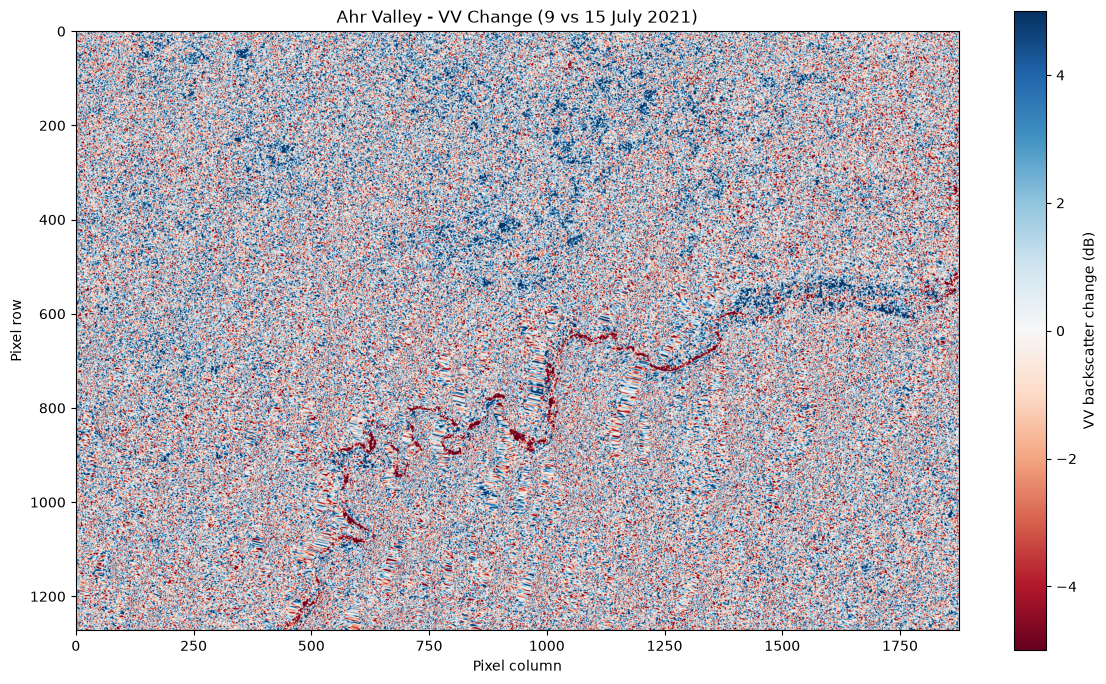

In [122]:
import matplotlib.pyplot as plt

# Visualize the original VV change raster
plt.figure(figsize=(12, 7))

img = plt.imshow(
    np.ma.masked_invalid(change_data),
    cmap="RdBu",
    vmin=-5,
    vmax=5
)

plt.colorbar(img, label="VV backscatter change (dB)")
plt.title("Ahr Valley - VV Change (9 vs 15 July 2021)")
plt.xlabel("Pixel column")
plt.ylabel("Pixel row")
plt.tight_layout()
plt.show()

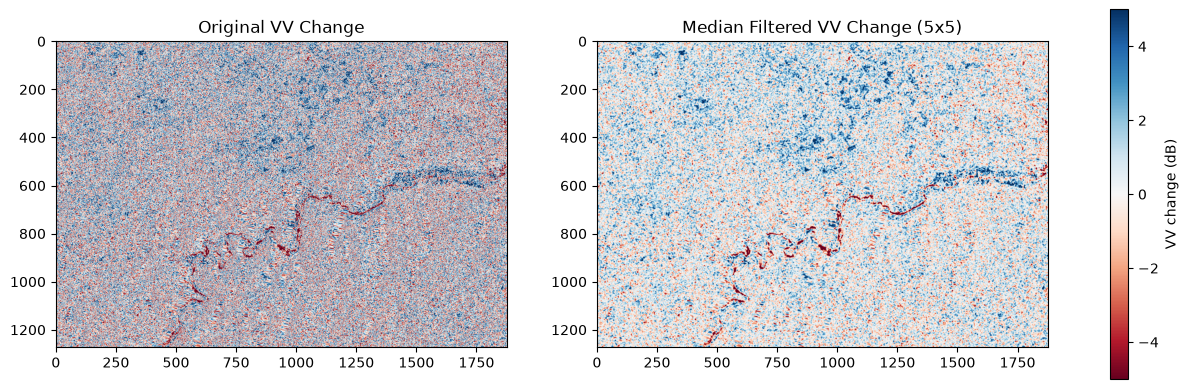

In [100]:
from scipy.ndimage import generic_filter

# Apply a 5x5 median filter to the change raster
filtered_change = generic_filter(
    change_data,
    function=np.nanmedian,
    size=5,
    mode="constant",
    cval=np.nan
)

# Compare original and filtered changes
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].imshow(
    np.ma.masked_invalid(change_data),
    cmap="RdBu",
    vmin=-5,
    vmax=5
)
axes[0].set_title("Original VV Change")

img = axes[1].imshow(
    np.ma.masked_invalid(filtered_change),
    cmap="RdBu",
    vmin=-5,
    vmax=5
)
axes[1].set_title("Median Filtered VV Change (5x5)")

fig.colorbar(
    img,
    ax=axes,
    label="VV change (dB)",
    shrink=0.8
)

plt.show()

Candidate pixels: 35150


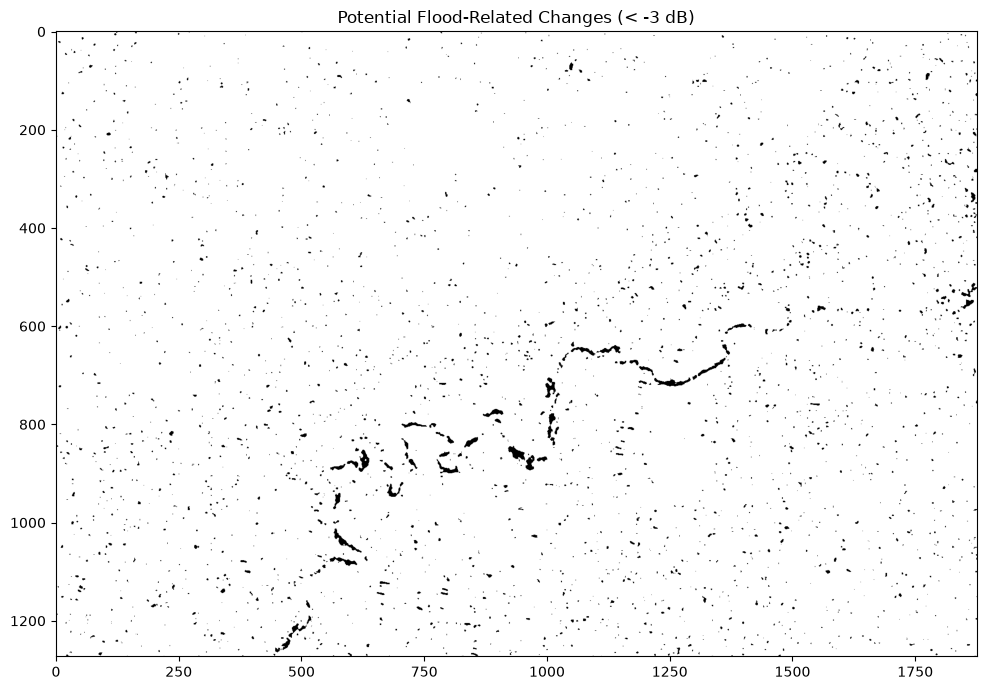

In [101]:
# Identify strong negative VV changes
threshold_db = -3.0

flood_candidates = (
    np.isfinite(filtered_change)
    & (filtered_change < threshold_db)
)

print("Candidate pixels:", flood_candidates.sum())

# Visualize candidate areas
plt.figure(figsize=(12, 7))
plt.imshow(flood_candidates, cmap="gray_r")
plt.title("Potential Flood-Related Changes (< -3 dB)")
plt.tight_layout()
plt.show()

In [102]:
from scipy.ndimage import label

# Identify connected candidate regions
structure = np.ones((3, 3), dtype=int)

labeled_regions, region_count = label(
    flood_candidates,
    structure=structure
)

region_sizes = np.bincount(labeled_regions.ravel())[1:]

print("Connected regions:", region_count)
print("Regions >= 5 pixels:", np.sum(region_sizes >= 5))
print("Regions >= 20 pixels:", np.sum(region_sizes >= 20))
print("Regions >= 50 pixels:", np.sum(region_sizes >= 50))
print("Largest region:", region_sizes.max() if region_count else 0)

Connected regions: 2958
Regions >= 5 pixels: 1689
Regions >= 20 pixels: 349
Regions >= 50 pixels: 71
Largest region: 570


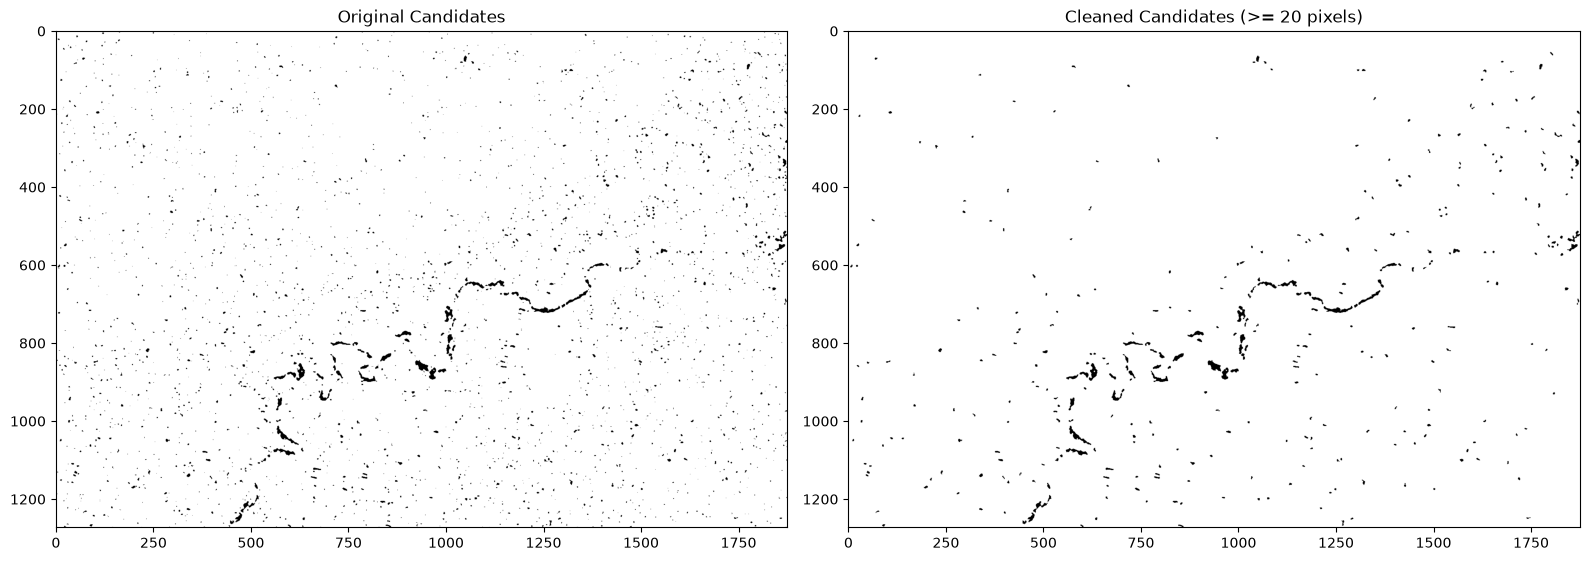

Original pixels: 35150
Remaining pixels: 19255


In [103]:
# Keep candidate regions with at least 20 pixels
min_region_size = 20

region_pixel_counts = np.bincount(labeled_regions.ravel())

cleaned_candidates = (
    flood_candidates
    & (region_pixel_counts[labeled_regions] >= min_region_size)
)

# Compare candidate maps
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].imshow(flood_candidates, cmap="gray_r")
axes[0].set_title("Original Candidates")

axes[1].imshow(cleaned_candidates, cmap="gray_r")
axes[1].set_title("Cleaned Candidates (>= 20 pixels)")

plt.tight_layout()
plt.show()

print("Original pixels:", flood_candidates.sum())
print("Remaining pixels:", cleaned_candidates.sum())

In [104]:
# Export cleaned candidate areas as a GeoTIFF
output_path = output_dir / "flood_candidates_cleaned.tif"

with rasterio.open(raster_path) as src:
    profile = src.profile.copy()

profile.update(
    dtype="uint8",
    count=1,
    nodata=255,
    compress="lzw"
)

# Encode candidate, background and NoData pixels
candidate_raster = cleaned_candidates.astype("uint8")
candidate_raster[~np.isfinite(change_data)] = 255

with rasterio.open(output_path, "w", **profile) as dst:
    dst.write(candidate_raster, 1)

print("Saved:", output_path)

Saved: outputs\orbit37\flood_candidates_cleaned.tif


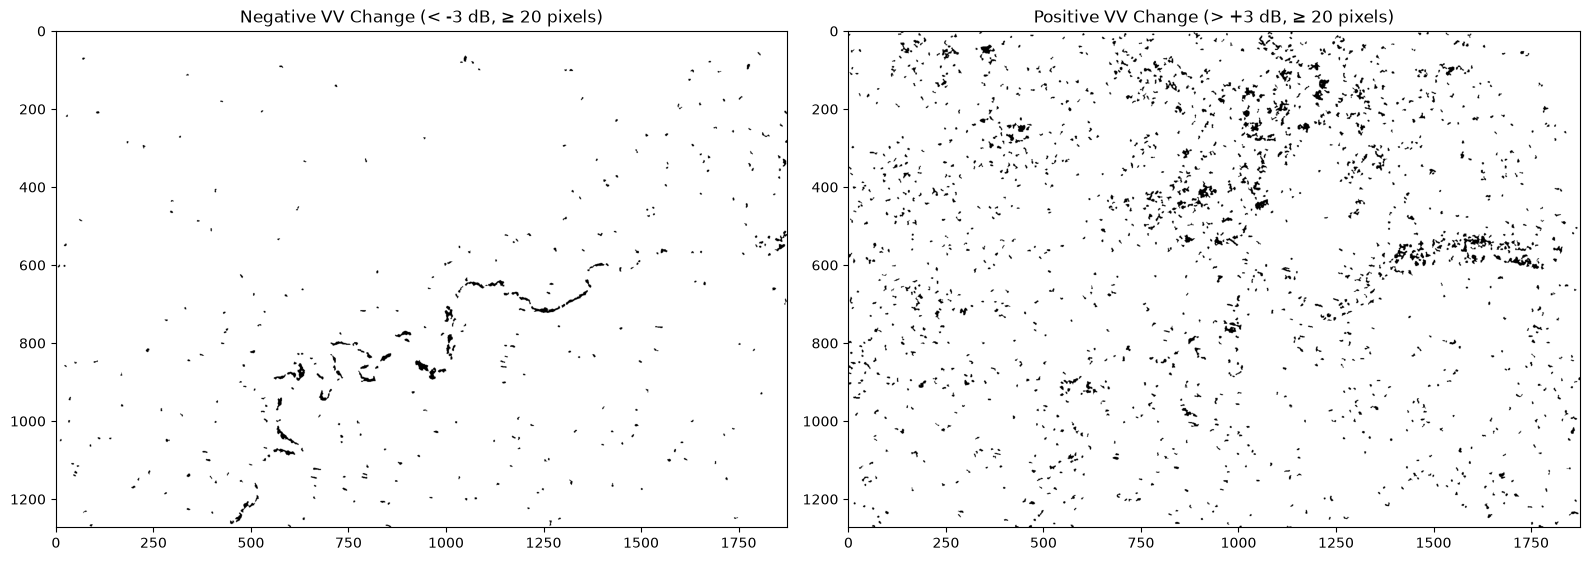

Negative change pixels: 19255
Positive change pixels: 76875


In [126]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import label

# Identify strong positive and negative SAR changes
negative_changes = np.isfinite(filtered_change) & (filtered_change < -3)
positive_changes = np.isfinite(filtered_change) & (filtered_change > 3)

# Remove connected regions smaller than 20 pixels
def remove_small_regions(mask, min_pixels=20):
    structure = np.ones((3, 3), dtype=np.uint8)
    labeled, _ = label(mask, structure=structure)
    sizes = np.bincount(labeled.ravel())
    return mask & (sizes[labeled] >= min_pixels)

negative_changes = remove_small_regions(negative_changes, 20)
positive_changes = remove_small_regions(positive_changes, 20)

# Compare cleaned positive and negative changes
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].imshow(negative_changes, cmap="gray_r")
axes[0].set_title("Negative VV Change (< -3 dB, ≥ 20 pixels)")

axes[1].imshow(positive_changes, cmap="gray_r")
axes[1].set_title("Positive VV Change (> +3 dB, ≥ 20 pixels)")

plt.tight_layout()
plt.show()

print("Negative change pixels:", negative_changes.sum())
print("Positive change pixels:", positive_changes.sum())

In [111]:
import numpy as np
import rasterio
from pathlib import Path

# Define output path
output_path = Path("outputs/orbit37/vv_change_classes.tif")

# Create a classified change raster
change_classes = np.zeros(change_data.shape, dtype=np.uint8)

# 1 = negative change, 2 = positive change
change_classes[negative_changes] = 1
change_classes[positive_changes] = 2

# Preserve invalid pixels as NoData
change_classes[~np.isfinite(change_data)] = 255

# Copy spatial metadata from the original raster
with rasterio.open("outputs/orbit37/openEO.tif") as src:
    profile = src.profile.copy()

profile.update(
    dtype="uint8",
    count=1,
    nodata=255,
    compress="lzw"
)

# Export classified changes
with rasterio.open(output_path, "w", **profile) as dst:
    dst.write(change_classes, 1)

print("Saved:", output_path)

Saved: outputs\orbit37\vv_change_classes.tif


In [112]:
# Find available WorldCover collections
collections = connection.list_collections()

worldcover_collections = [
    collection["id"]
    for collection in collections
    if "WORLDCOVER" in collection["id"].upper()
]

print("WorldCover collections:", worldcover_collections)

WorldCover collections: ['ESA_WORLDCOVER_10M_2020_V1', 'ESA_WORLDCOVER_10M_2021_V2']


In [113]:
# Inspect ESA WorldCover 2021 metadata
worldcover_metadata = connection.describe_collection(
    "ESA_WORLDCOVER_10M_2021_V2"
)

print("Available bands:")
for band in worldcover_metadata.get("summaries", {}).get("eo:bands", []):
    print(band)

print("\nCube dimensions:")
print(worldcover_metadata["cube:dimensions"])

Available bands:
{'aliases': ['Map'], 'data_type': 'uint8', 'gsd': 10, 'name': 'MAP'}

Cube dimensions:
{'bands': {'type': 'bands', 'values': ['MAP']}, 't': {'extent': ['2021-01-01T00:00:00Z', '2021-12-31T23:59:59Z'], 'type': 'temporal'}, 'x': {'axis': 'x', 'extent': [-180.0, 180.0], 'reference_system': 4326, 'step': 8.3333333333e-05, 'type': 'spatial'}, 'y': {'axis': 'y', 'extent': [-60.0, 84.0], 'reference_system': 4326, 'step': 8.3333333333e-05, 'type': 'spatial'}}


In [114]:
# Load ESA WorldCover 2021 for the Ahr Valley
worldcover_cube = connection.load_collection(
    "ESA_WORLDCOVER_10M_2021_V2",
    spatial_extent=bbox,
    temporal_extent=["2021-01-01", "2022-01-01"],
    bands=["MAP"]
)

# Remove the temporal dimension
worldcover_map = worldcover_cube.reduce_dimension(
    dimension="t",
    reducer="first"
)

print(worldcover_map)
print("Validation:", worldcover_map.validate())

DataCube(<ReduceNode 'reduce_dimension' at 0x2462c7a67b0>)
Validation: []


In [115]:
from pathlib import Path

# Create the WorldCover output directory
worldcover_dir = Path("outputs/worldcover")
worldcover_dir.mkdir(parents=True, exist_ok=True)

# Process and download ESA WorldCover 2021
worldcover_job = worldcover_map.create_job(
    out_format="GTiff",
    title="Ahr Valley ESA WorldCover 2021"
)

worldcover_job.start_and_wait()

# Download the completed results
files = worldcover_job.get_results().download_files(
    target=worldcover_dir
)

for file in files:
    print("Downloaded:", file)

0:00:00 Job 'j-2610151634414d968ead733c883c2fe1': send 'start'
0:00:01 Job 'j-2610151634414d968ead733c883c2fe1': created (progress 0%)
0:00:06 Job 'j-2610151634414d968ead733c883c2fe1': queued (progress 0%)
0:00:13 Job 'j-2610151634414d968ead733c883c2fe1': queued (progress 0%)
0:00:21 Job 'j-2610151634414d968ead733c883c2fe1': queued (progress 0%)
0:00:31 Job 'j-2610151634414d968ead733c883c2fe1': queued (progress 0%)
0:00:43 Job 'j-2610151634414d968ead733c883c2fe1': running (progress N/A)
0:00:58 Job 'j-2610151634414d968ead733c883c2fe1': running (progress N/A)
0:01:18 Job 'j-2610151634414d968ead733c883c2fe1': running (progress N/A)
0:01:42 Job 'j-2610151634414d968ead733c883c2fe1': finished (progress 100%)
Downloaded: outputs\worldcover\openEO.tif
Downloaded: outputs\worldcover\job-results.json


In [116]:
import numpy as np
import rasterio
from rasterio.warp import reproject, Resampling

# Reference SAR raster (Orbit 37 result)
sar_path = "outputs/orbit37/openEO.tif"

# Downloaded WorldCover raster
worldcover_path = "outputs/worldcover/openEO.tif"

# Open SAR raster to get target grid info
with rasterio.open(sar_path) as sar_src:
    sar_profile = sar_src.profile
    sar_crs = sar_src.crs
    sar_transform = sar_src.transform
    sar_shape = (sar_src.height, sar_src.width)

# Open WorldCover and reproject it onto the SAR grid
with rasterio.open(worldcover_path) as wc_src:
    worldcover_matched = np.full(sar_shape, 255, dtype=np.uint8)

    reproject(
        source=rasterio.band(wc_src, 1),
        destination=worldcover_matched,
        src_transform=wc_src.transform,
        src_crs=wc_src.crs,
        dst_transform=sar_transform,
        dst_crs=sar_crs,
        resampling=Resampling.nearest,
        dst_nodata=255
    )

# Define masks
builtup_mask = worldcover_matched == 50   # built-up
tree_mask = worldcover_matched == 10      # tree cover

print("Matched WorldCover shape:", worldcover_matched.shape)
print("Built-up pixels:", builtup_mask.sum())
print("Tree-cover pixels:", tree_mask.sum())

# Quick check of available classes after reprojection
unique_vals, counts = np.unique(worldcover_matched, return_counts=True)
for val, cnt in zip(unique_vals, counts):
    print(f"Class {val}: {cnt} pixels")

Matched WorldCover shape: (1273, 1876)
Built-up pixels: 111503
Tree-cover pixels: 1462884
Class 10: 1462884 pixels
Class 20: 1 pixels
Class 30: 441924 pixels
Class 40: 236624 pixels
Class 50: 111503 pixels
Class 60: 1088 pixels
Class 80: 872 pixels
Class 90: 1 pixels
Class 255: 133251 pixels


In [117]:
# Separate positive SAR changes by land cover
urban_positive = positive_changes & builtup_mask
forest_positive = positive_changes & tree_mask

# Calculate change percentages within each land-cover class
urban_percentage = 100 * urban_positive.sum() / builtup_mask.sum()
forest_percentage = 100 * forest_positive.sum() / tree_mask.sum()

print("Urban positive change pixels:", urban_positive.sum())
print("Forest positive change pixels:", forest_positive.sum())

print(f"Urban positive change: {urban_percentage:.2f}%")
print(f"Forest positive change: {forest_percentage:.2f}%")

Urban positive change pixels: 10531
Forest positive change pixels: 46041
Urban positive change: 9.44%
Forest positive change: 3.15%


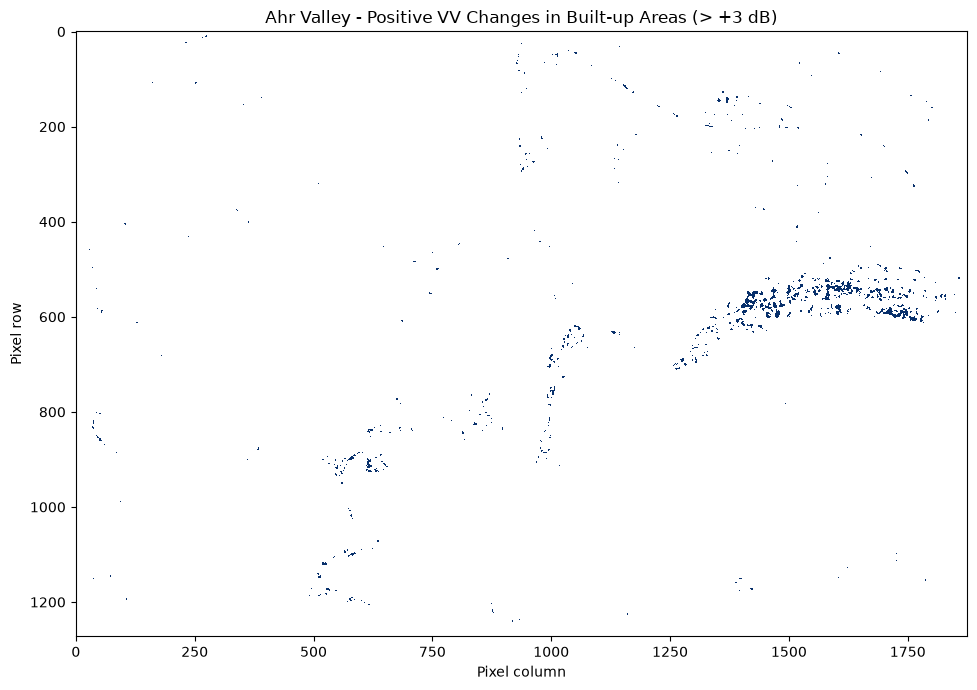

In [118]:
# Visualize positive SAR changes in built-up areas only
plt.figure(figsize=(12, 7))

plt.imshow(
    np.ma.masked_where(~urban_positive, urban_positive),
    cmap="Blues",
    vmin=0,
    vmax=1,
    interpolation="nearest"
)

plt.title("Ahr Valley - Positive VV Changes in Built-up Areas (> +3 dB)")
plt.xlabel("Pixel column")
plt.ylabel("Pixel row")
plt.tight_layout()
plt.show()

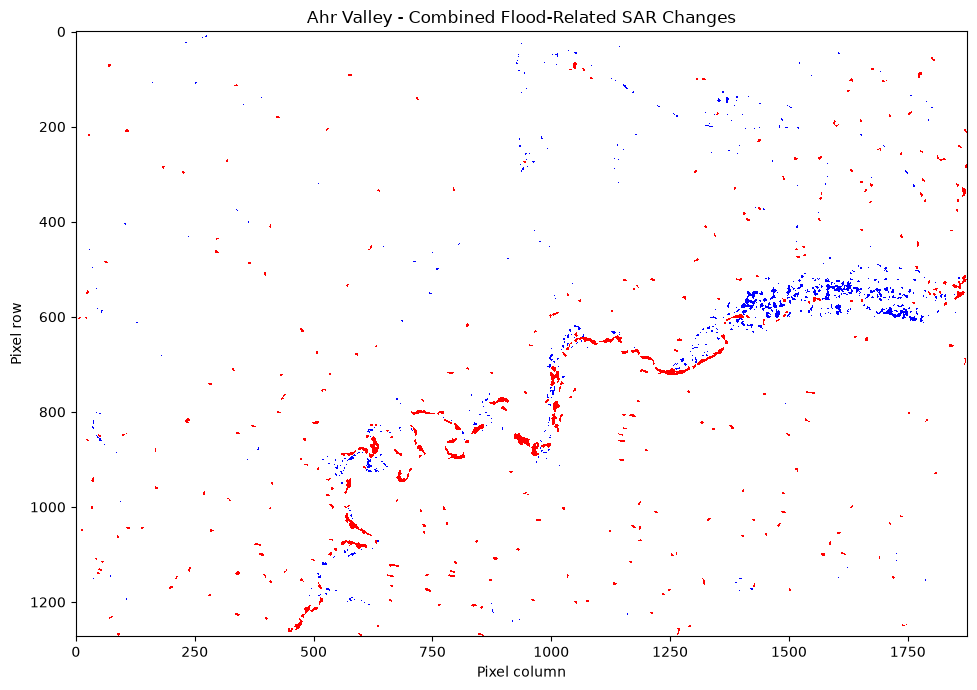

Negative change pixels: 19255
Positive urban pixels: 10531
Combined candidate pixels: 29786


In [119]:
# Combine negative changes with positive urban changes
final_candidates = cleaned_candidates | urban_positive

# Create a three-class change map
final_map = np.zeros(change_data.shape, dtype=np.uint8)

# 1 = negative change, 2 = positive urban change
final_map[cleaned_candidates] = 1
final_map[urban_positive] = 2

# Preserve NoData pixels
final_map[~np.isfinite(change_data)] = 255

# Visualize the combined candidate map
from matplotlib.colors import ListedColormap

cmap = ListedColormap(["white", "red", "blue"])

display_map = np.ma.masked_where(
    final_map == 255,
    final_map
)

plt.figure(figsize=(12, 7))

plt.imshow(
    display_map,
    cmap=cmap,
    vmin=0,
    vmax=2,
    interpolation="nearest"
)

plt.title("Ahr Valley - Combined Flood-Related SAR Changes")
plt.xlabel("Pixel column")
plt.ylabel("Pixel row")
plt.tight_layout()
plt.show()

print("Negative change pixels:", cleaned_candidates.sum())
print("Positive urban pixels:", urban_positive.sum())
print("Combined candidate pixels:", final_candidates.sum())

In [120]:
import rasterio
from pathlib import Path

# Define the combined change map output
output_path = Path("outputs/orbit37/combined_flood_candidates.tif")

# Copy the spatial metadata from the SAR raster
with rasterio.open("outputs/orbit37/openEO.tif") as src:
    profile = src.profile.copy()

profile.update(
    dtype="uint8",
    count=1,
    nodata=255,
    compress="lzw"
)

# Save the combined candidate classes
with rasterio.open(output_path, "w", **profile) as dst:
    dst.write(final_map, 1)

print("Saved:", output_path)

Saved: outputs\orbit37\combined_flood_candidates.tif


In [127]:
import rasterio

# Add a color table to the classified GeoTIFF
output_path = "outputs/orbit37/combined_flood_candidates.tif"

colormap = {
    0: (0, 0, 0, 0),        # Transparent background
    1: (255, 40, 40, 255),  # Red: negative VV change
    2: (30, 100, 255, 255), # Blue: positive urban VV change
    255: (0, 0, 0, 0)      # Transparent NoData
}

with rasterio.open(output_path, "r+") as dst:
    dst.write_colormap(1, colormap)